In [ ]:
# ==============================================================================
# TRABAJO FINAL: FUNDAMENTOS Y ALGORITMIA PARA INTELIGENCIA ARTIFICIAL
# Caso Práctico: DataExpert
# ==============================================================================

# --- CELDA 1: IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# --- CELDA 2: CARGA Y EXPLORACIÓN DEL DATASET (Pandas & NumPy) ---
np.random.seed(42)
n_samples = 50

# Creación del dataset sintético de 50 registros (7 características + 1 clase)
data = {
    'Area': np.random.normal(14.8, 2.0, n_samples),
    'Perimeter': np.random.normal(14.5, 1.0, n_samples),
    'Compactness': np.random.uniform(0.80, 0.90, n_samples),
    'Kernel_Length': np.random.normal(5.5, 0.4, n_samples),
    'Kernel_Width': np.random.normal(3.2, 0.2, n_samples),
    'Asymmetry_Coeff': np.random.normal(3.7, 1.0, n_samples),
    'Groove_Length': np.random.normal(5.4, 0.4, n_samples),
    'Class': np.random.choice([0, 1, 2], size=n_samples) # 3 Variedades
}

df = pd.DataFrame(data)

print("1. Primeros 5 registros del dataset:")
display(df.head())

print("\n2. Verificación de valores nulos:")
print(df.isnull().sum())

1. Primeros 5 registros del dataset:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coeff,Groove_Length,Class
0,15.793428,14.824084,0.841741,5.186699,3.294648,1.674857,5.339286,2
1,14.523471,14.114918,0.822211,5.371175,3.185434,3.886454,5.635327,2
2,16.095377,13.823078,0.811987,5.825407,3.030641,3.038214,5.512397,1
3,17.846060,15.111676,0.833762,5.007654,2.897031,4.552433,5.150920,2
4,14.331693,15.531000,0.894291,5.590984,3.110697,2.907479,5.316751,0



2. Verificación de valores nulos:
Area               0
Perimeter          0
Compactness        0
Kernel_Length      0
Kernel_Width       0
Asymmetry_Coeff    0
Groove_Length      0
Class              0
dtype: int64


In [ ]:
# --- CELDA 3: PREPROCESAMIENTO Y ESTANDARIZACIÓN ---
# Separación de características (X) y variable objetivo (y)
X = df.drop(columns=['Class'])
y = df['Class']

# Escalado numérico con StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Datos estandarizados Z-Score (Media=0, Desviación Estándar=1):")
display(X_scaled_df.head(5))

Datos estandarizados Z-Score (Media=0, Desviación Estándar=1):


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coeff,Groove_Length
0,0.781348,0.353888,-0.134086,-0.980341,0.349725,-1.700498,-0.490093
1,0.094354,-0.465448,-0.832835,-0.478974,-0.172756,0.247028,0.556390
2,0.944690,-0.802626,-1.198634,0.755529,-0.913292,-0.499930,0.121841
3,1.891737,0.686158,-0.419577,-1.466945,-1.552492,0.833488,-1.155952
4,-0.009390,1.170624,1.746024,0.118418,-0.530302,-0.615055,-0.569752


In [ ]:
# --- CELDA 4: OPERACIONES DE ÁLGEBRA LINEAL (NumPy) ---
# Vectores de prueba
u = df['Area'].values[:7]
v = df['Perimeter'].values[:7]

# Producto punto y norma euclidiana L2
dot_product = np.dot(u, v)
norm_u = np.linalg.norm(u)

print("--- ÁLGEBRA LINEAL CON NUMPY ---")
print(f"Vector u (Area[:7]): {np.round(u, 2)}")
print(f"Vector v (Perimeter[:7]): {np.round(v, 2)}")
print(f"Producto punto (u . v): {dot_product:.4f}")
print(f"Norma L2 de u (||u||): {norm_u:.4f}")

# Sistema de ecuaciones lineales Ax = b
A = np.array([[2, 1, -1],
              [-3, -1, 2],
              [-2, 1, 2]])
b = np.array([8, -11, -3])

x_sol = np.linalg.solve(A, b)
print("\nSolución del sistema de ecuaciones Ax = b:")
print(f"x, y, z = {x_sol}")

--- ÁLGEBRA LINEAL CON NUMPY ---
Vector u (Area[:7]): [15.79 14.52 16.1  17.85 14.33 14.33 17.96]
Vector v (Perimeter[:7]): [14.82 14.11 13.82 15.11 15.53 15.43 13.66]
Producto punto (u . v): 1620.3608
Norma L2 de u (||u||): 42.0857

Solución del sistema de ecuaciones Ax = b:
x, y, z = [ 2.  3. -1.]


In [ ]:
# --- CELDA 5: ANÁLISIS ESTADÍSTICO Y DETECCIÓN DE ATÍPICOS ---
# Medidas de tendencia central
media_area = np.mean(df['Area'])
mediana_area = np.median(df['Area'])
media_perim = np.mean(df['Perimeter'])
mediana_perim = np.median(df['Perimeter'])

# Funciones manuales sin librerías externas
def calcular_varianza_manual(datos):
    n = len(datos)
    mu = sum(datos) / n
    return sum((x - mu) ** 2 for x in datos) / n

def calcular_desviacion_manual(datos):
    return calcular_varianza_manual(datos) ** 0.5

# Comparación manual vs NumPy
var_manual = calcular_varianza_manual(df['Area'].values)
var_numpy = np.var(df['Area'].values)

std_manual = calcular_desviacion_manual(df['Area'].values)
std_numpy = np.std(df['Area'].values)

print("--- REPORTE ESTADÍSTICO ---")
print(f"Area -> Media: {media_area:.4f} | Mediana: {mediana_area:.4f}")
print(f"Perimeter -> Media: {media_perim:.4f} | Mediana: {mediana_perim:.4f}")
print(f"\nVarianza Area    -> Manual: {var_manual:.6f} | NumPy: {var_numpy:.6f}")
print(f"Desviación Area  -> Manual: {std_manual:.6f} | NumPy: {std_numpy:.6f}")

# Detección de atípicos con criterio de 2 desviaciones estándar
lim_inf = media_area - 2 * std_numpy
lim_sup = media_area + 2 * std_numpy
outliers = df[(df['Area'] < lim_inf) | (df['Area'] > lim_sup)]

print(f"\nOutliers detectados en 'Area' (Rango [{lim_inf:.2f}, {lim_sup:.2f}]): {len(outliers)}")

--- REPORTE ESTADÍSTICO ---
Area -> Media: 14.3491 | Mediana: 14.3317
Perimeter -> Media: 14.5178 | Mediana: 14.5461

Varianza Area    -> Manual: 3.417211 | NumPy: 3.417211
Desviación Area  -> Manual: 1.848570 | NumPy: 1.848570

Outliers detectados en 'Area' (Rango [10.65, 18.05]): 1


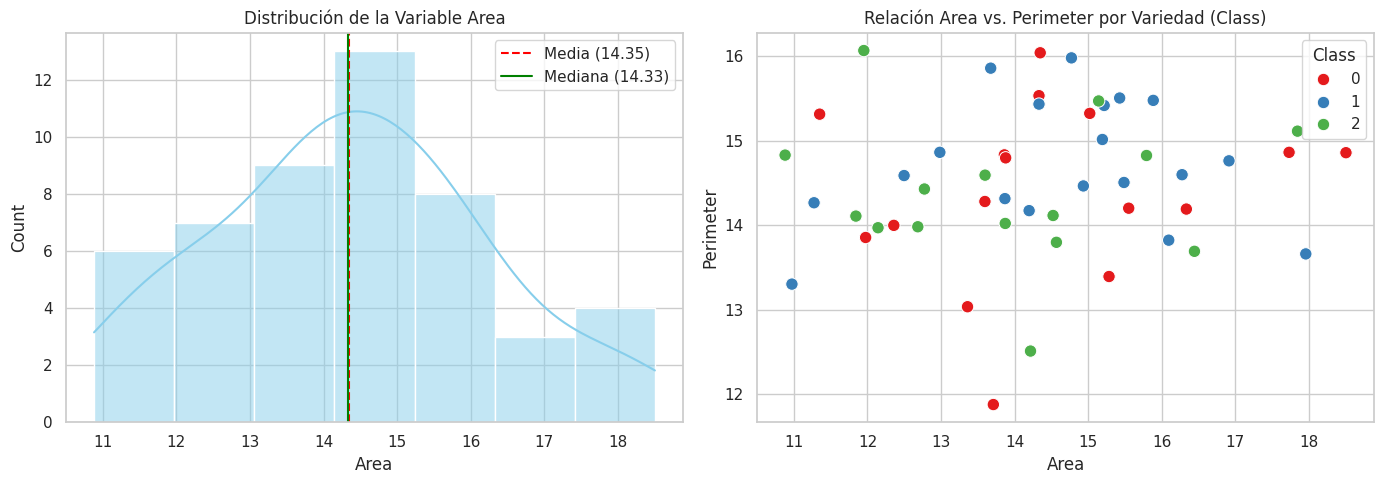

In [ ]:
# --- CELDA 6: VISUALIZACIÓN DE DATOS (Matplotlib & Seaborn) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Area
sns.histplot(df['Area'], kde=True, color='skyblue', ax=axes[0])
axes[0].axvline(media_area, color='red', linestyle='--', label=f'Media ({media_area:.2f})')
axes[0].axvline(mediana_area, color='green', linestyle='-', label=f'Mediana ({mediana_area:.2f})')
axes[0].set_title('Distribución de la Variable Area')
axes[0].legend()

# Scatter Plot Area vs Perimeter
sns.scatterplot(data=df, x='Area', y='Perimeter', hue='Class', palette='Set1', s=80, ax=axes[1])
axes[1].set_title('Relación Area vs. Perimeter por Variedad (Class)')

plt.tight_layout()
plt.show()

In [ ]:
# --- CELDA 7: ENTRENAMIENTO Y EVALUACIÓN DE MODELOS ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

# 1. K-Neighbors Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_knn = accuracy_score(y_test, knn.predict(X_test))

# 2. Decision Tree Classifier
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
acc_dt = accuracy_score(y_test, dt.predict(X_test))

print("--- EVALUACIÓN DE MODELOS DE CLASIFICACIÓN ---")
print(f"Accuracy KNN (k=5):          {acc_knn * 100:.2f}%")
print(f"Accuracy Árbol de Decisión: {acc_dt * 100:.2f}%")

--- EVALUACIÓN DE MODELOS DE CLASIFICACIÓN ---
Accuracy KNN (k=5):          26.67%
Accuracy Árbol de Decisión: 40.00%
